# Fashion-MNIST：第一个 MLP 训练闭环

这是练习 Notebook，核心实现由你完成。先只做第 1、2 节，再逐步推进。

选择上一级 `PyTorch/.venv/bin/python` 作为内核。正式实验前重启内核并从头运行；重复运行训练单元格会继续训练已有模型。

参考：[PyTorch Quickstart](https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html)

## 1. 导入与配置

统一使用教程的 `datasets.FashionMNIST` 和 transforms v2。Notebook 不使用 `__file__`；下面根据当前工作目录定位数据目录。

In [20]:
from pathlib import Path
import sys

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt



SEED = 42
torch.manual_seed(SEED)
DEVICE = "cpu"

cwd = Path.cwd()
PROJECT_DIR = cwd / "fashion_mnist_mlp" if (cwd / "fashion_mnist_mlp").is_dir() else cwd
DATA_DIR = PROJECT_DIR / "data"

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("数据目录:", DATA_DIR)

Python: /Users/zhengyangwu/Documents/CS/PyTorch/.venv/bin/python
PyTorch: 2.14.1
数据目录: /Users/zhengyangwu/Documents/CS/PyTorch/fashion_mnist_mlp/data


## 2. 加载数据，检查一个样本（当前任务）

将你已写的数据集构造代码放到下面，变量命名为 `training_data`。使用 `train=True`、`download=True`、`root=DATA_DIR`。

转换流程：`v2.ToImage()` → `v2.ToDtype(torch.float32, scale=True)`，用 `v2.Compose` 连接。

然后用索引 `[0]` 取出图像与标签，打印 shape、dtype、像素最小值/最大值和标签。

预期：图像 `[1, 28, 28]`、float32、像素在 `[0, 1]`；标签是 0–9 中的类别编号。首次下载需要联网。

In [10]:
# TODO：构造 training_data，再取出第一个样本并打印信息。
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

print(type(training_data))
print(len(training_data))  # 数据集有多少个样本

image, label = training_data[0]
print(type(image))
print(type(label))

print(image.shape)  # 预期：[1, 28, 28]
print(label)       # 一个整数类别编号
training_data.transform.type

image.shape

<class 'torchvision.datasets.mnist.FashionMNIST'>
60000
<class 'torchvision.tv_tensors._image.Image'>
<class 'int'>
torch.Size([1, 28, 28])
9


torch.Size([1, 28, 28])

**停下来解释：** 图像形状中的 1 是什么？标签为什么不是长度为 10 的向量？
是说颜色的表示吧，一个色块由一个0-1的数表示，不等同于位深度。

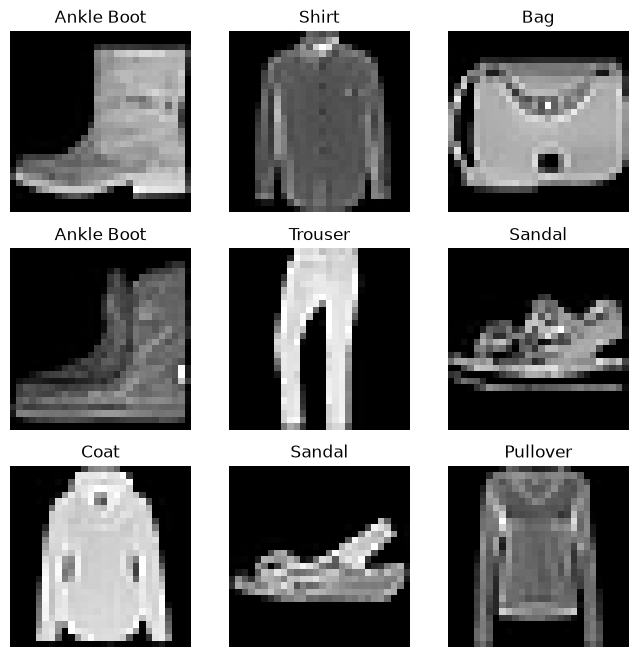

In [21]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

## 3. 划分数据与 DataLoader

将 training_data 固定划分为 54000 个训练样本和 6000 个验证样本。
提示：`random_split`，传入 `generator=torch.Generator().manual_seed(SEED)`。

创建 train_loader 和 val_loader，batch_size=64、num_workers=0；训练打乱，验证不打乱。官方 test 集留到最终评估。

In [16]:
# TODO：划分数据，创建两个 DataLoader。

train_dataloader = DataLoader(training_data, batch_size=64)
test_dataloader = DataLoader(test_data, batch_size=64)

In [18]:
# 完成上一格后运行这个检查。
images, labels = next(iter(train_dataloader))
print(images.shape, images.dtype)
print(labels.shape, labels.dtype)
assert images.shape == (64, 1, 28, 28)
assert labels.shape == (64,)
assert labels.dtype == torch.int64

torch.Size([64, 1, 28, 28]) torch.float32
torch.Size([64]) torch.int64


## 4. 定义 MLP，检查前向传播

实现一个 nn.Module：Flatten → Linear(784, 128) → ReLU → Linear(128, 10)。
可使用 nn.Sequential；别忘记 super().__init__()。输出原始 logits，不加 softmax。

先写出形状变化：[B, 1, 28, 28] → ? → ? → [B, 10]。

In [29]:
# TODO：定义 MLP 并创建 model，检查 model(images) 的形状。
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# Define model
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

torch.manual_seed(SEED)
model = NeuralNetwork()

for i in (0, 2):
    layer = model.linear_relu_stack[i]
    nn.init.kaiming_normal_(
        layer.weight,
        mode="fan_in",
        nonlinearity="relu",
    )

model = model.to(device)
lr = 1e-3
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

Using mps device


## 5. 训练前写假设

基线：SGD，lr=0.01，batch_size=64，5 epochs，seed=42，CPU。

- 我的假设：训练 loss 会……；验证 accuracy 会……
- 理由：……
- 这是首次基线；后续实验每次只修改一个主要变量。

把假设与最终结果同时记录到 experiments.md。

## 6. 完成一个 batch 的更新

创建 nn.CrossEntropyLoss 和 torch.optim.SGD。优化器需要 model.parameters()。

自己安排步骤：前向传播、计算损失、清空梯度、反向传播、更新参数。
损失输入为 [B, 10] logits 与 [B] int64 标签，输出是标量。

定位提示：检查 loss.item()、某层 weight.grad，以及更新前后权重是否变化。保存更新前权重时应使用 detach().clone()，避免与原参数共享存储。

In [31]:
# TODO：只做一个 batch 的更新，检查参数是否变化。
loss_fn = nn.CrossEntropyLoss()

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        ratio = (
            lr * layer.weight.grad.std()
            / layer.weight.std()
        )
        
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

train(train_dataloader, model, loss_fn, optimizer)

loss: 1.404361  [   64/60000]
loss: 1.373729  [ 6464/60000]
loss: 1.146801  [12864/60000]
loss: 1.278787  [19264/60000]
loss: 1.112403  [25664/60000]
loss: 1.071952  [32064/60000]
loss: 1.129954  [38464/60000]
loss: 1.008330  [44864/60000]
loss: 1.048630  [51264/60000]
loss: 0.973607  [57664/60000]


In [26]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

## 7. 扩展为训练与验证循环

训练：model.train()，遍历 batch，累计指标并更新参数。
验证：model.eval() 与 torch.no_grad()，只统计指标。思考两者职责有什么区别。

平均 loss：累计每个 batch 的平均损失 × 该 batch 样本数，再除以总样本数。
accuracy：总正确预测数 / 总样本数；提示 logits.argmax(dim=1)。

正式基线开始前重新设置随机种子、创建模型和优化器，避免把第 6 节的更新带入实验。打印每个 epoch 的 train/validation loss 与 accuracy。

In [27]:
# TODO：实现训练、评估函数，并连接 5 epochs 的训练闭环。
epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.174287  [   64/60000]
loss: 2.158543  [ 6464/60000]
loss: 2.102683  [12864/60000]
loss: 2.117488  [19264/60000]
loss: 2.057899  [25664/60000]
loss: 2.002821  [32064/60000]
loss: 2.028729  [38464/60000]
loss: 1.951916  [44864/60000]
loss: 1.972971  [51264/60000]
loss: 1.881201  [57664/60000]
Test Error: 
 Accuracy: 54.1%, Avg loss: 1.885400 

Epoch 2
-------------------------------
loss: 1.927637  [   64/60000]
loss: 1.888671  [ 6464/60000]
loss: 1.776635  [12864/60000]
loss: 1.814595  [19264/60000]
loss: 1.689431  [25664/60000]
loss: 1.651767  [32064/60000]
loss: 1.664606  [38464/60000]
loss: 1.570858  [44864/60000]
loss: 1.600087  [51264/60000]
loss: 1.480678  [57664/60000]
Test Error: 
 Accuracy: 59.4%, Avg loss: 1.505173 

Epoch 3
-------------------------------
loss: 1.578342  [   64/60000]
loss: 1.536275  [ 6464/60000]
loss: 1.390132  [12864/60000]
loss: 1.456530  [19264/60000]
loss: 1.326618  [25664/60000]
loss: 1.338512  [32064/600

## 8. 记录与解释

| epoch | train loss | train accuracy | validation loss | validation accuracy |
|---|---|---|---|---|

- 实际观察：
- 假设是否得到支持：
- 可能原因与不确定性：

第一阶段到此为止。曲线、TensorBoard、BatchNorm 与结构对照实验在闭环通过后逐步加入。